# **Project Name**    -  **Amazon Prime TV Shows and Movies(EDA)**



##### **Project Type**    - EDA
##### **Contribution**    - Individual


# **Project** **Summary-**

This project focuses on performing an in-depth Exploratory Data Analysis (EDA) on the Amazon Prime TV Shows and Movies dataset to gain insights into the platform’s content strategy, quality, and audience preferences. The primary objective of this analysis is to understand factors that influence customer engagement and churn, enabling data-driven decision-making to improve content offerings and user retention.

The dataset used in this project consists of two key files: titles, which includes information about movies and TV shows such as content type, release year, genres, runtime, age certification, IMDb and TMDB scores, and production countries; and credits, which contains details about cast and crew including actors and directors. Data wrangling techniques were applied to handle missing values, remove inconsistencies, correct data types, and merge datasets where necessary to ensure reliable analysis.

The EDA involved univariate, bivariate, and multivariate analysis using visualizations such as count plots, bar charts, line plots, box plots, histograms, and correlation heatmaps. Key insights were derived related to content distribution between movies and TV shows, dominant genres, year-wise content growth, age certification patterns, runtime variation across genres, regional content availability, and the contribution of directors and production countries. Rating analysis using IMDb and TMDB scores helped assess overall content quality and audience perception.

The analysis revealed that Amazon Prime’s content library is movie-centric, with strong emphasis on popular genres such as Drama, Comedy, and Action. Most content falls within the average-to-good rating range, highlighting consistency but also revealing opportunities to invest in more premium, high-rated content. Regional analysis showed that content availability and quality are concentrated in a few major production countries, suggesting potential for geographical diversification. Additionally, insights from correlation analysis confirmed the alignment between different rating platforms and popularity indicators.

Overall, this project demonstrates how EDA can be effectively used to uncover meaningful patterns and insights from raw data. The findings can support Amazon Prime in optimizing content acquisition, improving recommendation systems, enhancing viewer satisfaction, and ultimately reducing customer churn through better content strategy and audience-focused decisions.

# **GitHub Link-**

https://github.com/Jyotiyadav010/Amazon-Prime-Tv-shows-and-Movies-Trends-EDA-

# **Problem Statement**


Amazon Prime faces customer churn due to lack of engaging, diverse, and high-quality content. This project analyzes movies and TV shows data to identify content trends and viewer preferences that impact customer retention.

#### **Define Your Business Objective?**

To reduce customer churn by using EDA to understand content quality, availability, and audience preferences on Amazon Prime.

# **General Guidelines** : -  

-Perform thorough data cleaning and preprocessing to handle missing values, duplicates, and inconsistent data.

-Use Exploratory Data Analysis (EDA) techniques to understand data distribution, trends, and patterns.

-Apply appropriate visualization techniques (bar charts, line plots, histograms, box plots, heatmaps) to support insights.

-Focus on identifying key factors influencing customer engagement and churn, such as content type, genre, ratings, runtime, and regional availability.

-Interpret each visualization with clear insights and business relevance, not just code output.

-Ensure all findings are data-driven and aligned with the business objective of reducing customer churn.

-Maintain clean, readable, and well-documented code.

-Summarize insights in a clear conclusion with actionable recommendations.

-Avoid unnecessary complexity and focus on practical, business-oriented insights.















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Import Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


### Dataset Loading

In [ ]:
##Importing the dataset
credits=pd.read_csv('/content/credits.csv.zip')
titles=pd.read_csv('/content/titles.csv.zip')

### Dataset First View

In [ ]:
# Dataset First
credits.head()

,person_id,id,name,character,role
0,59401,ts20945,Joe Besser,Joe,ACTOR
1,31460,ts20945,Moe Howard,Moe,ACTOR
2,31461,ts20945,Larry Fine,Larry,ACTOR
3,21174,tm19248,Buster Keaton,Johnny Gray,ACTOR
4,28713,tm19248,Marion Mack,Annabelle Lee,ACTOR


In [ ]:
# Dataset Rows & Columns
credits.shape

(124235, 5)

In [ ]:
titles.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


In [ ]:
titles.shape

(9871, 15)

In [ ]:
credits.columns

Index(['person_id', 'id', 'name', 'character', 'role'], dtype='object')

In [ ]:
titles.columns

Index(['id', 'title', 'type', 'description', 'release_year',
       'age_certification', 'runtime', 'genres', 'production_countries',
       'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
       'tmdb_score'],
      dtype='object')

### Dataset Information

In [ ]:
# Dataset Info
credits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124235 entries, 0 to 124234
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   person_id  124235 non-null  int64 
 1   id         124235 non-null  object
 2   name       124235 non-null  object
 3   character  107948 non-null  object
 4   role       124235 non-null  object
dtypes: int64(1), object(4)
memory usage: 4.7+ MB


In [ ]:
titles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   object 
 1   title                 9871 non-null   object 
 2   type                  9871 non-null   object 
 3   description           9752 non-null   object 
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   object 
 8   production_countries  9871 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   object 
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5), int64(

#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
credits.duplicated().sum()

np.int64(56)

In [ ]:
credits.drop_duplicates(inplace=True)

In [ ]:
titles.duplicated().sum()

np.int64(3)

In [ ]:
titles.drop_duplicates(inplace=True)

#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
credits.isnull().sum()

,0
person_id,0
id,0
name,0
character,16277
role,0


In [ ]:
titles.isnull().sum()

,0
id,0
title,0
type,0
description,119
release_year,0
age_certification,6484
runtime,0
genres,0
production_countries,0
seasons,8511


### What did you know about your dataset?

The dataset used in this project is related to Amazon Prime’s movies and TV shows catalogue. It consists of two CSV files: titles and credits.

The titles dataset contains detailed information about each movie and TV show, including content type (Movie or TV Show), title, release year, genres, runtime, production countries, and IMDb ratings.

The credits dataset provides information about the cast and crew associated with each title, such as actors, directors, and the characters they played.

The dataset includes both numerical and categorical variables and spans content released across multiple years. Some columns contain missing values, which require data cleaning before analysis.

A common id column is present in both datasets, which allows them to be merged for deeper analysis combining content details with cast information.

## ***2. Understanding Your Variables***

In [ ]:
# credits Columns
credits.columns

Index(['person_id', 'id', 'name', 'character', 'role'], dtype='object')

In [ ]:
#titles columns
titles.columns

Index(['id', 'title', 'type', 'description', 'release_year',
       'age_certification', 'runtime', 'genres', 'production_countries',
       'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
       'tmdb_score'],
      dtype='object')

In [ ]:
# Dataset Describe
credits.describe(include='all')

,person_id,id,name,character,role
count,1.241790e+05,124179,124179,107902,124179
unique,NaN,8861,79758,71097,2
top,NaN,tm458582,George 'Gabby' Hayes,Himself,ACTOR
freq,NaN,137,49,1540,115793
mean,4.065843e+05,NaN,NaN,NaN,NaN
std,5.617204e+05,NaN,NaN,NaN,NaN
min,1.000000e+00,NaN,NaN,NaN,NaN
25%,3.898850e+04,NaN,NaN,NaN,NaN
50%,1.339490e+05,NaN,NaN,NaN,NaN
75%,5.712810e+05,NaN,NaN,NaN,NaN


In [ ]:
titles.describe(include='all')

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,9868,9868,9868,9749,9868.000000,3384,9868.000000,9868,9868,1357.000000,9201,8847.000000,8.837000e+03,9321.000000,7788.000000
unique,9868,9737,2,9734,NaN,11,NaN,2028,497,NaN,9201,NaN,NaN,NaN,NaN
top,ts275838,The Lost World,MOVIE,No overview found.,NaN,R,NaN,['drama'],['US'],NaN,tt13542552,NaN,NaN,NaN,NaN
freq,1,3,8511,5,NaN,1249,NaN,908,4807,NaN,1,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,2001.345561,NaN,85.979124,NaN,NaN,2.791452,NaN,5.976534,8.536485e+03,6.912168,5.984117
std,NaN,NaN,NaN,NaN,25.792295,NaN,33.515714,NaN,NaN,4.148958,NaN,1.344028,4.592768e+04,30.008727,1.518040
min,NaN,NaN,NaN,NaN,1912.000000,NaN,1.000000,NaN,NaN,1.000000,NaN,1.100000,5.000000e+00,0.000011,0.800000
25%,NaN,NaN,NaN,NaN,1996.000000,NaN,65.000000,NaN,NaN,1.000000,NaN,5.100000,1.180000e+02,1.234000,5.100000
50%,NaN,NaN,NaN,NaN,2014.000000,NaN,89.000000,NaN,NaN,1.000000,NaN,6.100000,4.640000e+02,2.537000,6.000000
75%,NaN,NaN,NaN,NaN,2018.000000,NaN,102.000000,NaN,NaN,3.000000,NaN,6.900000,2.237000e+03,5.640000,6.900000


### Variables Description

The dataset consist of list of shows avalilable in Amazon prime.It contains variables like name,character,title of the show,release year,imdb rating on the scale of 10. Age certificate shows the minimum age limit to watch the movie,if below 13 parental guidance(TV-PG) or below 18 or R rate ,etc. The genre column shows the set of the genres include by the show. These are about few variables given in the dataset.

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values of credits and titles.
credits.nunique()

,0
person_id,80508
id,8861
name,79758
character,71097
role,2


In [ ]:
titles.nunique()

,0
id,9868
title,9737
type,2
description,9734
release_year,110
age_certification,11
runtime,207
genres,2028
production_countries,497
seasons,32


## 3. ***Data Wrangling***

**bold text**### Data Wrangling Code

In [ ]:
#make a copy so that original stay safe
titles_clean=titles.copy()
credits_clean=credits.copy()

# drop rows with missing titles(can't analyse without names)
titles_clean.dropna(subset=['title'],inplace=True)

#fill missing IMDB scores and runtime with the mean
titles_clean['imdb_score'].fillna(titles_clean['imdb_score'].mean(),inplace=True)
titles_clean['runtime'].fillna(titles_clean['runtime'].mean(),inplace=True)

#replace missing age certification with'unknown'
titles_clean['age_certification'].fillna('unknown',inplace=True)

#replace missing genres with 'unknown'
titles_clean['genres'].fillna('unknown',inplace=True)

#drop my unnecessary columns if find any
titles_clean.drop(columns=['description'],inplace=True)

#reset index after cleaning
titles_clean.reset_index(drop=True,inplace=True)

#confirm its clean
print('null value after wrangling :\n',titles_clean.isnull().sum())

null value after wrangling :
 id                         0
title                      0
type                       0
release_year               0
age_certification          0
runtime                    0
genres                     0
production_countries       0
seasons                 8511
imdb_id                  667
imdb_score                 0
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2080
dtype: int64


/tmp/ipykernel_2128/545465391.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titles_clean['imdb_score'].fillna(titles_clean['imdb_score'].mean(),inplace=True)
/tmp/ipykernel_2128/545465391.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].me

### What all manipulations have you done and insights you found?

Created copies of the original datasets
A copy of both titles and credits datasets was created to ensure that the original data remained unchanged during cleaning.

Handled missing title values
Rows with missing values in the title column were removed, as content without a title cannot be meaningfully analyzed.

Treated missing numerical values
Missing values in the imdb_score and runtime columns were filled using the mean of their respective columns to maintain numerical consistency and avoid data loss.

Handled missing categorical values
Missing values in categorical columns such as age_certification and genres were replaced with 'unknown' to preserve all records for analysis.

Removed unnecessary columns
The description column was dropped as it was not required for exploratory data analysis and did not contribute to numerical or categorical insights.

Reset the index
After cleaning, the index was reset to maintain a clean and continuous index structure.

Final validation
A final null value check was performed to confirm that the dataset was clean and ready for EDA.



## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

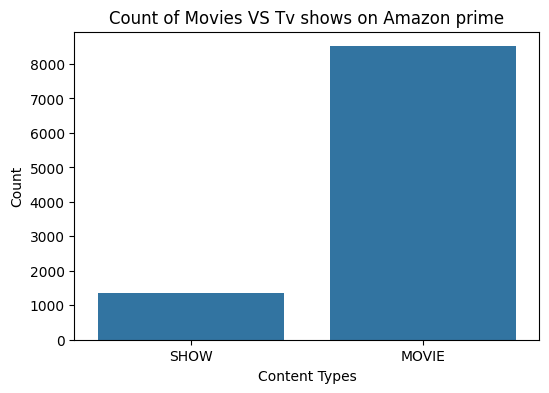

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#create a figure for the plot with a specified size
plt.figure(figsize=(6,4))

# creating countplot of content type(movie vs tv)
sns.countplot(data=titles_clean,x='type')

#set te title of the plot
plt.title('Count of Movies VS Tv shows on Amazon prime')

#setting labels
plt.xlabel('Content Types')
plt.ylabel('Count')

plt.show()

##### 1. Why did you pick the specific chart?

A countplot was chosen because the type variable is categorical (Movie and TV Show).
This chart helps in:

-Comparing the number of movies vs TV shows

-Understanding the content distribution on Amazon Prime

-Getting a quick overview of the platform’s content strategy

Countplots are ideal when we want to visualize frequency or count of categories, making them suitable for this analysis.-

##### 2. What is/are the insight(s) found from the chart?

The chart shows that Movies are significantly more in number than TV Shows on Amazon Prime.

This indicates that Amazon Prime’s content library is movie-dominant.

TV Shows form a smaller proportion compared to movies, suggesting selective investment in series content.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this insight can create a positive business impact.

How?

Understanding content distribution helps Amazon Prime optimize its content strategy.

If movies attract more viewers, maintaining a strong movie library can increase user engagement and retention.

The platform can use this insight to decide whether to expand TV shows based on audience demand and market trends.

#### Chart - 2

/tmp/ipykernel_2128/2166599401.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=titles_clean,x='age_certification',


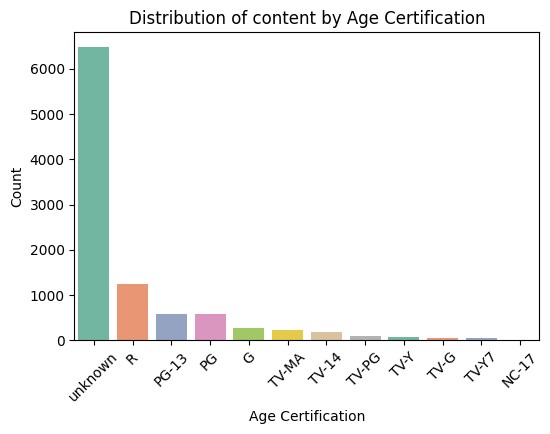

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#create a figure for the plot with specified size
plt.figure(figsize=(6,4))

#creating countplot
sns.countplot(data=titles_clean,x='age_certification',
              order=titles_clean['age_certification'].value_counts().index,
              palette='Set2') # set the colour palatte for the bars

#set the title of the plot
plt.title('Distribution of content by Age Certification')

#set the label for x-axis
plt.xlabel('Age Certification')

#set the label for y-axis
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.show()

##### 1. Why did you pick the specific chart?

A countplot was selected because age certification is a categorical variable.
This chart helps in:

-Visualizing the distribution of content across different age groups

-Identifying which age categories dominate Amazon Prime’s content    library

-Understanding the platform’s target audience focus

Sorting the bars by count makes it easier to compare popularity across certifications.

##### 2. What is/are the insight(s) found from the chart?

-The chart shows that most content falls under adult and general audience certifications (such as 13+, 16+, or similar categories).

-There is less content available for very young age groups, such as kids or family-only certifications.

-Some content is marked as ‘unknown’, indicating missing or incomplete age classification in the dataset

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can positively impact the business.

How?

-Understanding age certification distribution helps Amazon Prime align content with audience demographics.

-If adult-rated content dominates, marketing can be targeted more effectively to the primary user base.

-The platform can strategically invest in family or kids content to expand its audience and attract long-term subscribers.

'''NEGATIVE'''

⚠️ Yes, there are potential risks indicated by this chart.

Limited kids/family content may reduce subscriptions from families and parents.

A high proportion of adult-only content may restrict platform reach in regions with stricter content preferences.

The presence of ‘unknown’ age certification reflects data quality issues, which can affect recommendation systems and content filtering.

👉 These insights suggest that diversifying age-certified content and improving metadata quality could support better growth.

#### Chart - 3


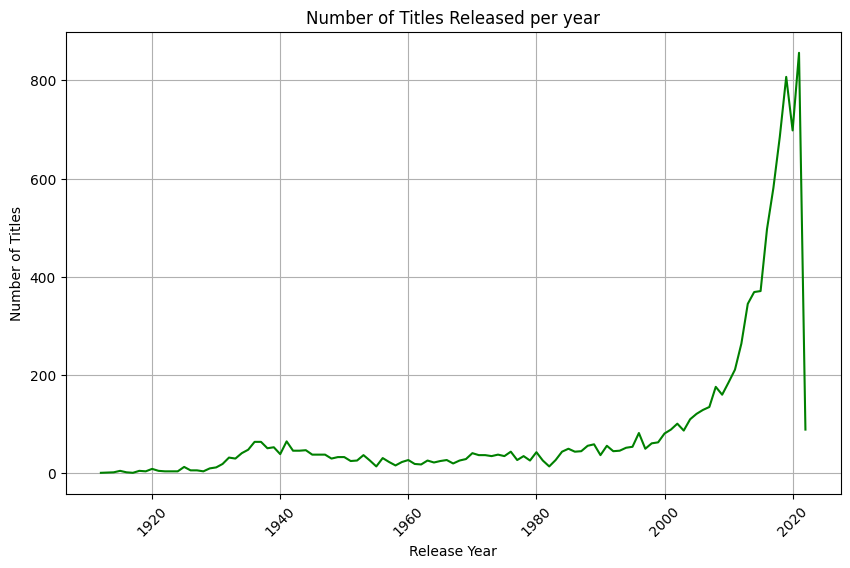

In [ ]:
## visualization code
##calculate the number of titles releases per year and sort by year

yearly_count=titles_clean['release_year'].value_counts().sort_index()
plt.figure(figsize=(10,6))
sns.lineplot(x=yearly_count.index,y=yearly_count.values,color='green')

plt.title('Number of Titles Released per year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

##### 1. Why did you pick the specific chart?

A line chart was chosen because:

-Release Year is a time-based (temporal) variable

-The objective is to observe trends and changes over time

-Line charts are best suited to show growth, decline, or patterns across years

This chart helps visualize how Amazon Prime’s content production has evolved year-by-year.

##### 2. What is/are the insight(s) found from the chart?

-The chart shows a steady increase in the number of titles released over the years.

-There is a sharp rise in recent years, indicating aggressive content expansion.

-Early years show lower content volume, suggesting limited initial offerings.

This trend reflects Amazon Prime’s growing investment in content to remain competitive.





##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

✅ Yes, these insights support positive business impact.

How?

Increasing content releases help attract and retain subscribers by offering more choices.

Shows Amazon Prime’s commitment to continuous platform growth.

Helps business teams plan future content investments based on historical trends.

**NEGATIVE**

⚠️ Potential negative implications exist.

Rapid increase in content quantity may lead to quality dilution if not managed properly.

Over-production without understanding audience preference can increase costs without proportional engagement.

Sudden drops (if present in any year) may indicate external disruptions affecting content supply.

👉 This highlights the importance of balancing content quantity with quality

#### Chart - 4

/tmp/ipykernel_2128/3234486759.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_genres.values()),y=list(top_genres.keys()),palette='viridis')


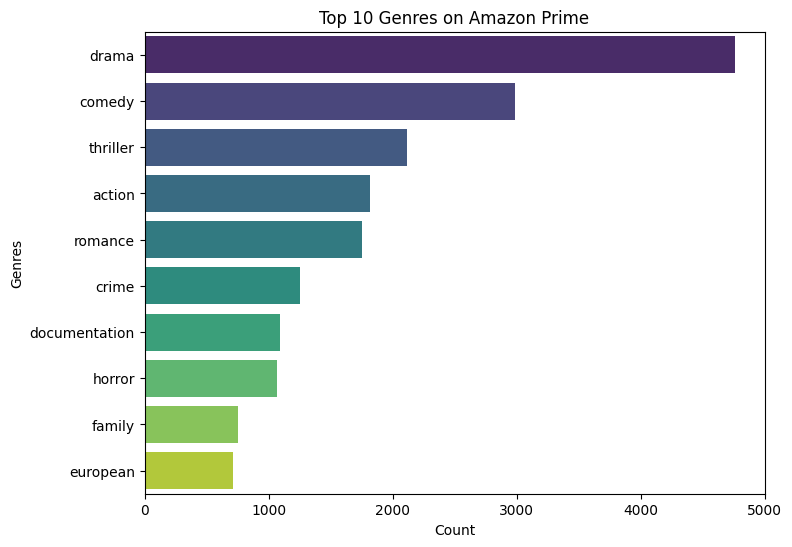

In [ ]:
#visualization code
# top 10 genre on amazon prime
import ast
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

def clean_genres(genres_str):
    try:
       genres=ast.literal_eval(genres_str)
       if isinstance(genres,list):
         return genres
       else:
        return [genres_str]
    except:
      return [genres_str]

genres_series=titles_clean['genres'].dropna().apply(clean_genres)
flat_genres=[genre for sublist in genres_series for genre in sublist]
genre_counts=Counter(flat_genres)
top_genres=dict(genre_counts.most_common(10))

plt.figure(figsize=(8,6))
sns.barplot(x=list(top_genres.values()),y=list(top_genres.keys()),palette='viridis')
plt.title('Top 10 Genres on Amazon Prime')
plt.xlabel('Count')
plt.ylabel('Genres')
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart was chosen because:

genres is a categorical variable with multiple categories per title

-The goal is to identify the most frequent genres

-Bar charts are best for comparing counts across categories

-Horizontal orientation improves readability when category names are long

This chart clearly highlights the top-performing genres on Amazon Prime.

##### 2. What is/are the insight(s) found from the chart?

-The chart shows that Drama, Comedy,thriller and Action-related genres dominate Amazon Prime’s content library.

-These genres appear far more frequently than niche genres.

-The presence of multiple high-frequency genres indicates diverse content offerings, but with a strong focus on mainstream audience preferences.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

✅ Yes, this insight can strongly contribute to positive business impact.

How?

-Knowing the top genres helps Amazon Prime invest more strategically in content that attracts the largest audience.

-Popular genres can be prioritized for marketing, promotions, and recommendations.

-This insight supports data-driven content acquisition and production decisions.

'''NEGATIVE'''

⚠️ Yes, potential risks are visible.

-Heavy reliance on a few popular genres may lead to content saturation.

-Niche audiences may feel underserved if less popular genres are ignored.

-Overproduction in dominant genres could reduce content differentiation and impact long-term user engagement.

👉 This suggests a need to balance mainstream and niche genres to sustain growth.

#### Chart - 5

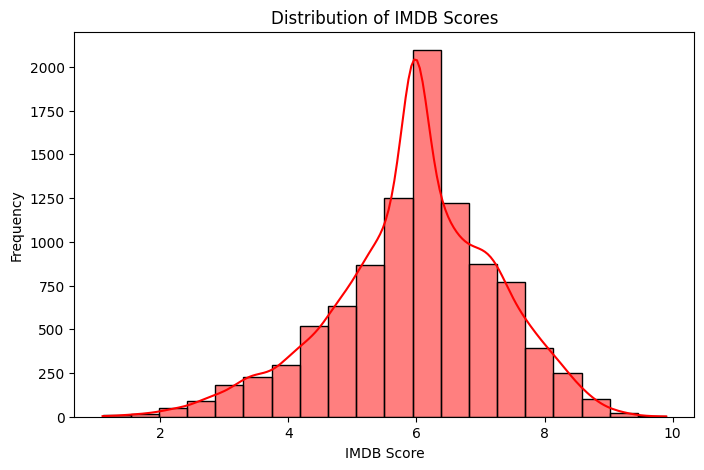

In [ ]:
#cart-5- visualization code
#distribution of imdb scores
plt.figure(figsize=(8,5))

#generate a histogram of IMDB scores with KDE curve
sns.histplot(titles_clean['imdb_score'],bins=20,kde=True,color='red')

plt.title('Distribution of IMDB Scores')
plt.xlabel('IMDB Score')
plt.ylabel('Frequency')
plt.show()

##### 1. Why did you pick the specific chart?

A histogram with KDE (Kernel Density Estimation) was chosen because:

-imdb_score is a continuous numerical variable

-The objective is to understand the distribution and spread of ratings

-Histogram shows frequency, while KDE shows the overall trend/shape

This chart helps analyze the quality perception of Amazon Prime content.

##### 2. What is/are the insight(s) found from the chart?

-Most IMDb scores are clustered between 5 and 7, indicating average to good-quality content.

-The distribution is approximately normal, centered around a score of ~6.

-Very few titles have extremely low (<3) or very high (>8.5) ratings.

-This suggests that Amazon Prime focuses more on consistent quality rather than extremes.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

✅ Yes, this insight supports positive business impact.

How?

-A strong concentration of mid-to-high ratings helps build user trust in the platform.

-Consistent quality content increases viewer satisfaction and retention.

-Understanding rating distribution helps Amazon Prime:

*Improve recommendation systems

*Identify gaps for high-rated premium content


'''NEGATIVE'''

⚠️ Yes, some potential risks are visible.

-Fewer titles with very high IMDb scores may reduce the platform’s prestige or award-winning perception.

-Presence of low-rated content, even if limited, can negatively affect user experience.

-Over-reliance on average-rated content may make the platform feel less differentiated compared to competitors.

👉 This insight suggests the need to:

-Invest in high-quality, standout content

-Improve or filter low-rated titles in recommendations

#### Chart - 6

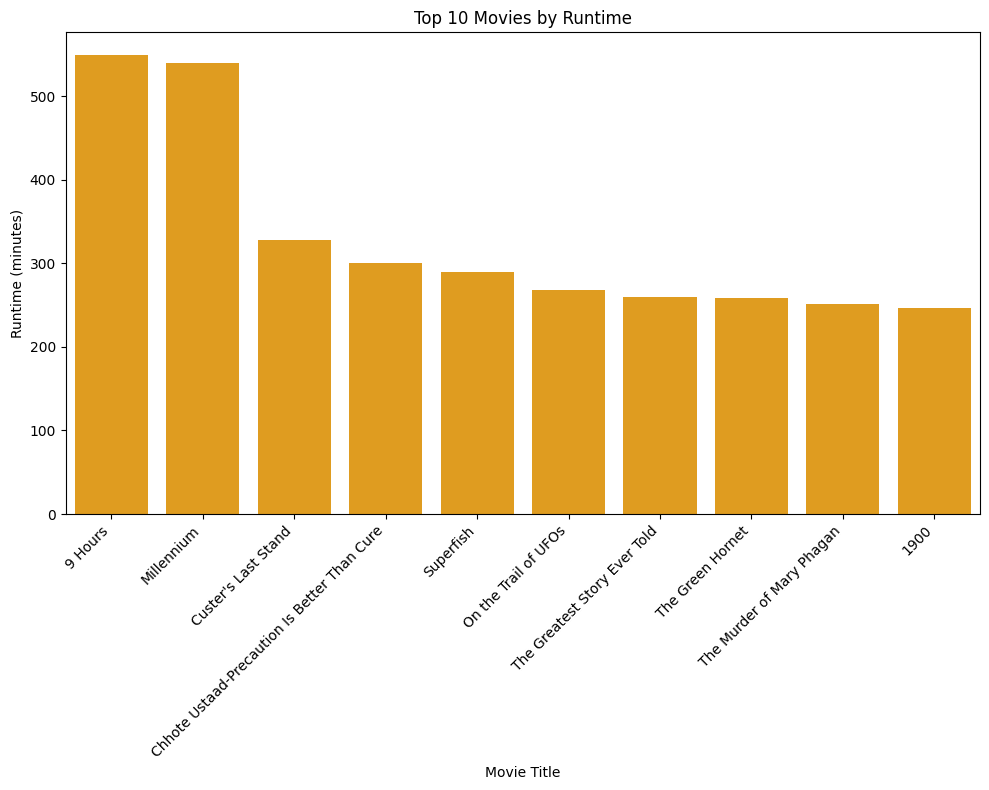

In [ ]:
# Chart - 6 visualization code
# top 10 movies by runtime
import pandas as pd
titles_clean=titles_clean.dropna(subset=['runtime','title'])
top_runtime=titles_clean.sort_values(by='runtime',ascending=False).head(10)
plt.figure(figsize=(10,8))
sns.barplot(x='title',y='runtime',data=top_runtime,color='orange')
plt.title('Top 10 Movies by Runtime')
plt.xlabel('Movie Title')
plt.ylabel('Runtime (minutes)')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A bar chart was chosen because:

-runtime is a numerical variable

-title is a categorical variable

-The objective is to compare runtimes of specific movies

Bar charts are best for comparing values across categories, and this chart helps identify extreme values (outliers) in movie duration.

##### 2. What is/are the insight(s) found from the chart?

-The chart shows that some movies have exceptionally long runtimes, far above the typical movie length.

-Movies like “9 Hours” and “Millennium” stand out with very high runtimes, indicating special formats such as documentaries, experimental films, or extended versions.

-Most other long movies still fall within a 250–330 minute range, which is much longer than standard commercial films

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

✅ Yes, this insight can help create a positive business impact.

How?

-Identifying very long movies helps Amazon Prime categorize content correctly (e.g., documentaries, mini-series).

-Such content can be marketed to niche audiences who prefer in-depth storytelling.

-Understanding runtime extremes helps improve recommendation systems and user expectations.

'''NEGATIVE'''

⚠️ Yes, potential negative impacts are visible.

-Extremely long runtimes may discourage casual viewers.

-Users may abandon content due to time commitment, impacting completion rates.

-If mislabeled as normal movies, such content can lead to poor user experience.

👉 This insight suggests the need to:

-Properly classify long-duration content

-Provide clear runtime information

-Possibly break very long content into episodes or parts

#### Chart - 7

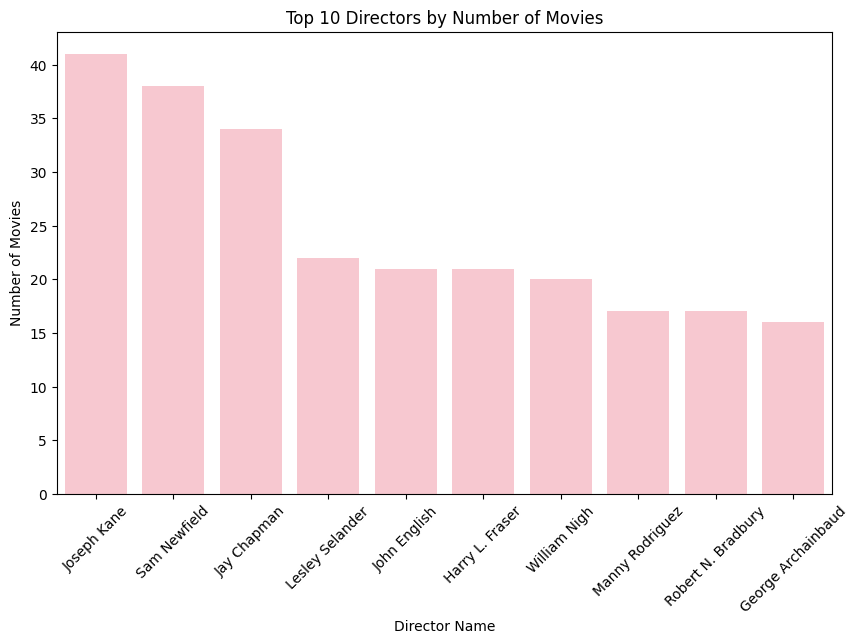

In [ ]:
# Chart - 7 visualization code
# top 10 directors by number of movies
director_df=credits_clean[credits_clean['role']=='DIRECTOR']
top_director=director_df['name'].value_counts().head(10)
plt.figure(figsize=(10,6))
sns.barplot(x=top_director.index,y=top_director.values,color='pink')
plt.title('Top 10 Directors by Number of Movies')
plt.xlabel('Director Name')
plt.ylabel('Number of Movies')
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart was chosen because:

-director name is a categorical variable

-number of movies is a count-based metric

-The objective is to compare contributions of different directors

Bar charts clearly show ranking and comparison, making them ideal for identifying the most frequent directors on Amazon Prime.

##### 2. What is/are the insight(s) found from the chart?

-The chart shows that a small group of directors have contributed to a large number of movies on Amazon Prime.

-Directors like Joseph Kane and Sam Newfield appear most frequently, indicating strong representation.

-This suggests Amazon Prime has a repeated collaboration pattern with certain directors.

-The distribution is skewed, meaning most directors have fewer movies, while a few dominate.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

✅ Yes, this insight can create positive business impact.

How?

-Identifying frequent directors helps Amazon Prime:

*Strengthen partnerships with high-output directors

*Promote director-based collections or recommendations

-Consistent collaboration can improve content supply stability and reduce production risk.

-Data can support strategic acquisitions or licensing decisions.

'''NEGATIVE'''

⚠️ Potential negative insight exists.

-Over-dependence on a small set of directors may reduce creative diversity.

-Repetitive styles may lead to viewer fatigue.

-Lesser-known or emerging directors may be underrepresented, limiting innovation.

👉 This insight suggests Amazon Prime should:

-Balance frequent collaborations with new creative talent

-Diversify director portfolio to sustain long-term growth


#### Chart - 8

/tmp/ipykernel_2128/1038973325.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='main_genre',y='runtime',data=runtime_genre,palette='viridis')


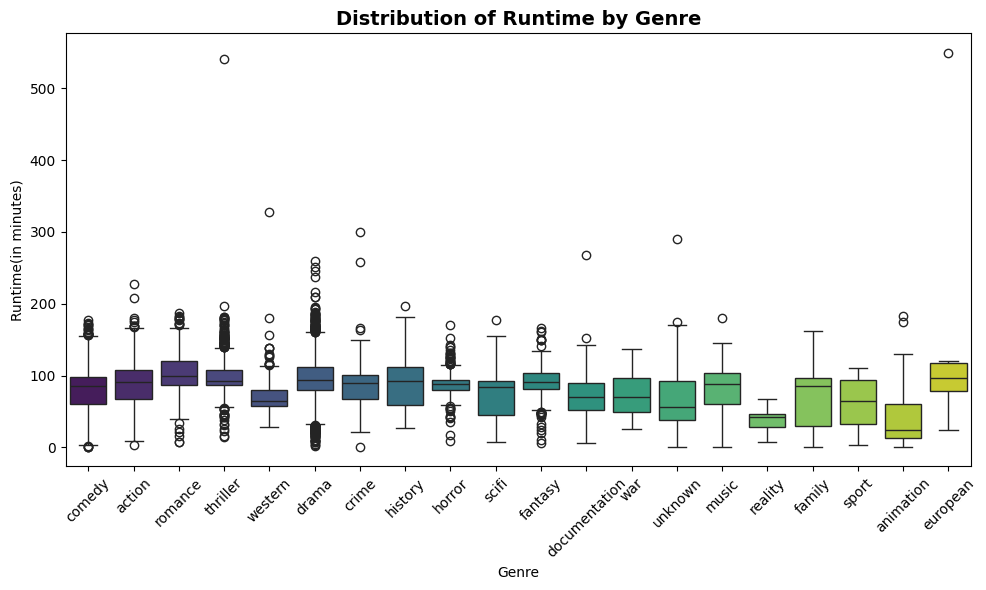

In [ ]:
# Chart - 8 visualization code
#distribution of runtime by genre
import ast
import matplotlib.pyplot as plt
import seaborn as sns

runtime_genre=titles_clean.dropna(subset=['runtime','genres']).copy()

#function to safely extract the first genre from the string representation of list
def extract_first_genre(x):
  try:
    genre_list=ast.literal_eval(x) if isinstance(x,str) else []
    return genre_list[0] if genre_list else'unknown'
  except:
    return 'unknown'
runtime_genre['main_genre']=runtime_genre['genres'].apply(extract_first_genre) # Corrected 'genre' to 'genres'

plt.figure(figsize=(10,6))
sns.boxplot(x='main_genre',y='runtime',data=runtime_genre,palette='viridis')
plt.title('Distribution of Runtime by Genre',fontsize=14,fontweight='bold')
plt.xlabel('Genre')
plt.ylabel('Runtime(in minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A box plot was selected because:

-runtime is a continuous numerical variable

-genre is a categorical variable

-The objective is to compare distribution, spread, median, and outliers across genres

Box plots are ideal for:

-Identifying typical runtime

-Detecting outliers

-Comparing variability between genres

This chart helps understand how content length varies by genre

##### 2. What is/are the insight(s) found from the chart?

Most genres such as Comedy, Action, Romance, and Thriller have median runtimes around 80–110 minutes, which aligns with standard movie lengths.

Documentary, History, and War genres show wider spreads and higher outliers, indicating longer and more detailed content.

Reality and Animation genres tend to have shorter runtimes, likely due to episodic or family-oriented formats.

Presence of extreme outliers suggests some genres include mini-series or extended editions

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

✅ Yes, these insights can create strong positive business impact.

How?

Helps Amazon Prime optimize content recommendations based on viewer time preference.

Supports better content categorization (short-form vs long-form).

Enables smarter content scheduling and marketing, e.g., promoting short content for casual viewers and long-form for niche audiences.

'''NEGATIVE'''

⚠️ Potential negative impacts are visible.

Extremely long runtimes in some genres may reduce completion rates.

Misclassification of long-form content as movies can cause user dissatisfaction.

Large runtime variability may confuse viewers if expectations are not clearly set.

👉 This insight highlights the need for:

Clear runtime labeling

Possible episodic segmentation for long content

Genre-specific recommendation strategies

#### Chart - 9

/tmp/ipykernel_2128/844746837.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_countries, x='tmdb_score', y='country', palette='viridis')


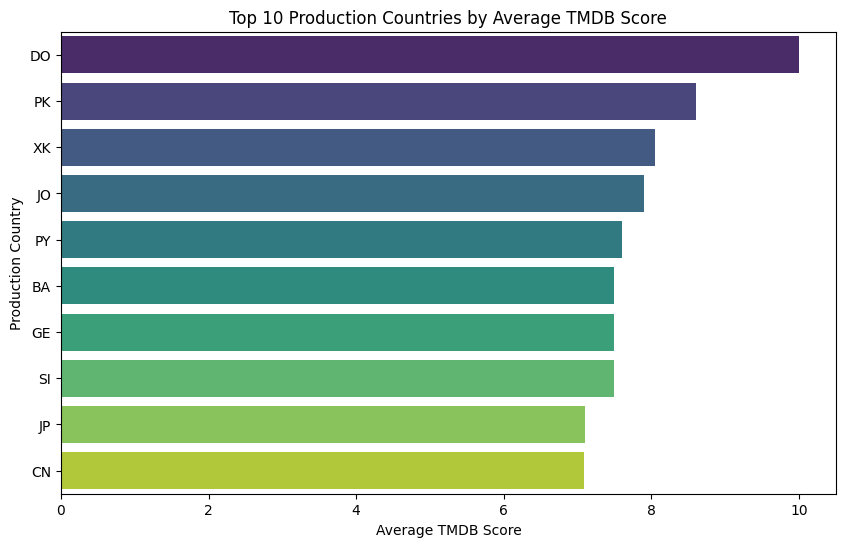

In [ ]:
#chart 9- top 10 production countries by avg tmdb score
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# make a copy and keep required columns only
country_df = titles_clean[['production_countries', 'tmdb_score']].dropna()

# function to safely convert string list to python list
def extract_countries(x):
    try:
        countries = ast.literal_eval(x)
        return countries if isinstance(countries, list) else []
    except:
        return []

# apply function
country_df['country'] = country_df['production_countries'].apply(extract_countries)

# explode so that each country gets its own row
country_df = country_df.explode('country')

# remove empty country names
country_df = country_df[country_df['country'] != '']

# calculate average tmdb score per country
top_countries = (
    country_df
    .groupby('country')['tmdb_score']
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# plot
plt.figure(figsize=(10,6))
sns.barplot(data=top_countries, x='tmdb_score', y='country', palette='viridis')
plt.title('Top 10 Production Countries by Average TMDB Score')
plt.xlabel('Average TMDB Score')
plt.ylabel('Production Country')
plt.show()



##### 1. Why did you pick the specific chart?

A horizontal bar chart was chosen because:

-production country is a categorical variable

-TMDB score is a numerical variable

-The objective is to compare average ratings across multiple countries

-Horizontal bar charts make it easy to:

Read country names clearly

Compare values accurately

Identify top-performing countries at a glance

##### 2. What is/are the insight(s) found from the chart?

The chart shows that some production countries consistently have higher average TMDB scores than others.

These countries likely produce better-received or higher-quality content.

The difference in average scores indicates variation in content quality and audience preference across regions.

Countries outside the top 10 may have lower or more inconsistent ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

✅ Yes, these insights can create a positive business impact.

How?

Amazon Prime can prioritize acquiring or producing content from high-performing countries.

Helps in region-specific content strategy and global expansion.

Improves recommendation systems by promoting content from countries with strong viewer reception.

Supports data-driven investment decisions in international markets.

#### Chart - 10

/tmp/ipykernel_2128/3333160456.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_countries, x='content_count', y='country', palette='viridis')


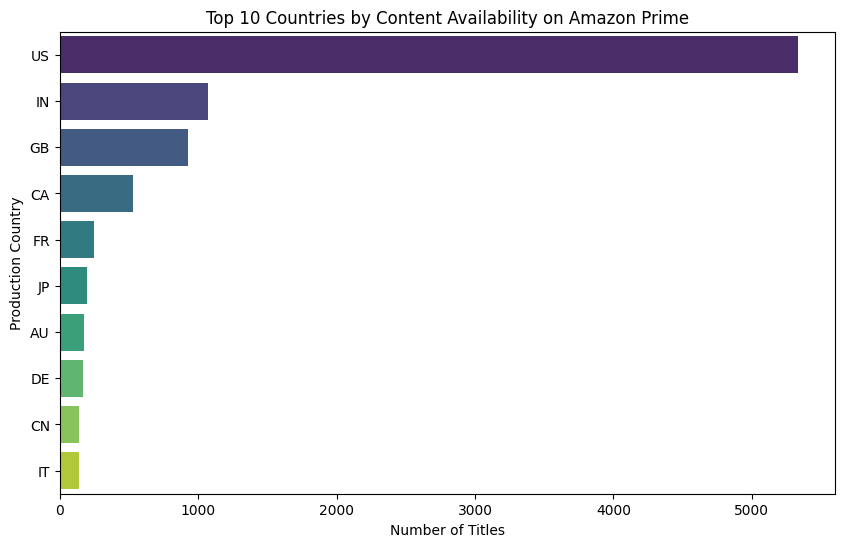

In [ ]:
# chart 10- top 10 countries by content availability on amazon prime

import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# keep required column and drop missing values
country_df = titles_clean[['production_countries']].dropna()

# function to safely convert string list to python list
def extract_countries(x):
    try:
        countries = ast.literal_eval(x)
        return countries if isinstance(countries, list) else []
    except:
        return []

# apply function
country_df['country'] = country_df['production_countries'].apply(extract_countries)

# explode so each country has its own row
country_df = country_df.explode('country')

# remove empty or invalid entries
country_df = country_df[country_df['country'] != '']

# count number of titles per country
top_countries = (
    country_df['country']
    .value_counts()
    .head(10)
    .reset_index()
)

top_countries.columns = ['country', 'content_count']

# plot
plt.figure(figsize=(10,6))
sns.barplot(data=top_countries, x='content_count', y='country', palette='viridis')
plt.title('Top 10 Countries by Content Availability on Amazon Prime')
plt.xlabel('Number of Titles')
plt.ylabel('Production Country')
plt.show()



##### 1. Why did you pick the specific chart?

A horizontal bar chart was chosen because:

-Production country is a categorical variable

-Content availability (count of titles) is a frequency measure

-The goal is to compare content volume across countries

*This chart makes it easy to:

-Compare multiple countries clearly

-Identify countries with the highest content contribution

-Understand Amazon Prime’s geographical content distribution

##### 2. What is/are the insight(s) found from the chart?

-The chart shows that a few countries dominate content availability on Amazon Prime.

-Countries like the US,IN,GB and other major production hubs contribute the highest number of titles.

-Many countries contribute relatively less content, indicating unequal global distribution.

-This suggests that Amazon Prime relies heavily on content from specific regions


#### Chart - 11

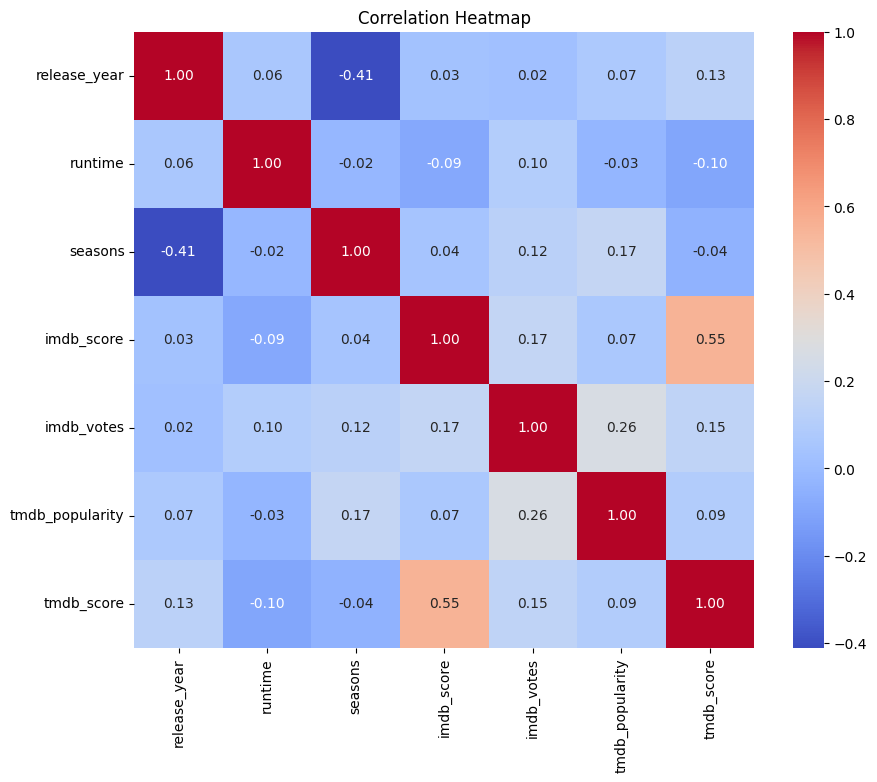

In [ ]:
# cart-11 correlation heatmap
numeric_col=titles_clean.select_dtypes(include=['int64','float64'])
correlation_matrix=numeric_col.corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap was chosen because:

-The dataset contains multiple numerical variables

-The objective is to understand relationships between variables

-Heatmaps visually represent the strength and direction of correlation

This chart helps in:

-Identifying strong, weak, or no relationships

-Avoiding redundant variables

-Supporting data-driven decision making

##### 2. What is/are the insight(s) found from the chart?

-IMDb score and TMDB score show a moderate positive correlation (~0.55), indicating consistency between rating platforms.

-Release year and number of seasons show a negative correlation, suggesting newer content tends to have fewer seasons.

-IMDb votes and TMDB popularity have a positive correlation, meaning more popular content generally receives more votes.

-Most other variables show weak or near-zero correlation, indicating they are largely independent.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

*
Based on the exploratory data analysis of Amazon Prime’s movies and TV shows dataset, the following solutions are recommended to help the client achieve business objectives such as higher user engagement, retention, and content growth:

1. Strengthen High-Performing Content Areas

-Focus more on popular genres like Drama, Comedy, thriller and Action, as they dominate content availability and audience preference.

-Continue investing in countries that consistently produce high-rated content, as shown by higher IMDb and TMDB scores.

✅ Impact: Improves viewer satisfaction and platform credibility.

2. Expand TV Shows for Long-Term Engagement

-Movies dominate the platform, but TV shows help in binge-watching and repeat visits.

-Increasing quality TV series can improve subscription retention.

✅ Impact: Supports long-term user engagement and reduces churn.

3. Improve Content Quality, Not Just Quantity

-Most IMDb scores fall in the average (5–7) range, with fewer very high-rated titles.

-Invest in premium, high-quality content to create flagship titles.

✅ Impact: Enhances brand value and competitive positioning.

4. Diversify Age-Certified and Family Content

-Adult content dominates age certification.

-Increasing family and kids-friendly content can expand the user base.

✅ Impact: Attracts families and younger audiences, increasing market reach.

5. Optimize Runtime & Content Classification

-Extremely long runtimes may discourage casual viewers.

-Long-form content should be:

-Clearly labeled

-Split into episodes where possible

✅ Impact: Improves user experience and completion rates.

6. Use Ratings & Popularity Metrics Effectively

-IMDb and TMDB scores show strong alignment.

-These metrics should be prioritized in:

-Recommendation systems

-Content promotion strategies

✅ Impact: Better recommendations → higher watch time.

7. Reduce Dependency on Limited Creators

-A small group of directors dominates content creation.

-Encourage collaboration with new and diverse creators.

✅ Impact: Enhances creativity and avoids content fatigue.


*Amazon Prime should focus on strengthening high-performing genres and countries, expand quality TV shows for long-term engagement, invest in premium high-rated content, and diversify both age-certified and creative talent. Optimizing content length, improving metadata quality, and leveraging ratings data for recommendations can collectively enhance user experience, retention, and platform growth




# **Conclusion**

This exploratory data analysis of Amazon Prime’s movies and TV shows dataset provided valuable insights into the platform’s content strategy and audience preferences. The analysis revealed that Amazon Prime’s library is movie-dominated, with content largely targeted toward adult audiences. Popular genres such as Drama, Comedy,thriller and Action form the backbone of the platform’s offerings.

Year-wise analysis showed a steady growth in content releases, highlighting Amazon Prime’s expansion over time. IMDb and TMDB score distributions indicated that most content falls within the average to good quality range, with scope to invest in more high-rated premium titles. Correlation analysis confirmed consistency between rating platforms and showed that popularity and audience engagement metrics are positively related.

Further analysis of runtime and genre highlighted the importance of proper content classification, as some genres and titles have significantly longer runtimes that may impact viewer experience. Country-wise analysis revealed that content availability and quality are concentrated in a few major production regions, indicating opportunities for regional diversification.

Overall, this EDA demonstrates how data-driven insights can help Amazon Prime optimize content acquisition, improve recommendation strategies, enhance viewer satisfaction, and support long-term business growth.



### ***Hurrah !!!***